## Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Data Reading

In [2]:
df=pd.read_csv(r"..\data\raw\company_A_labelled_subset.csv")

## Data acquisition

- **ts: (string)** a timestamp in the format YYYY-MM-DD HH:mm:ss+TZ;
- **asset: (string)** an identifier for the machine used;
- **items: (int)** the number of items produced in the time span;
- **status: (int)** the machine state where 0 is idle, 1 is manual production mode, 2 is automatic production mode and 3 is an alarm or interrupted state;
- **power_avg: (int)** the average power consumed, in kilo-watts;
- **cycle_time: (int)** the total time, in seconds, to produce the items;
- **product: (int)** a product identifier ranging from 0 to 13.

In [3]:
df

,ts,asset,items,status,status_time,power_avg,cycle_time,alarm,product
0,2022-08-31 22:00:00+00:00,0,4.0,2.0,43.0,2.0,0.0,0,0
1,2022-08-31 22:00:00+00:00,1,8.0,2.0,20.0,2.0,0.0,0,1
2,2022-08-31 22:05:00+00:00,1,9.0,2.0,38.0,1.0,0.0,0,1
3,2022-08-31 22:10:00+00:00,1,8.0,2.0,39.0,1.0,0.0,0,1
4,2022-08-31 22:10:00+00:00,0,8.0,2.0,3.0,6.0,0.0,0,0
...,...,...,...,...,...,...,...,...,...
14487,2022-09-21 15:35:00+00:00,2,0.0,1.0,60.0,0.0,0.0,0,12
14488,2022-09-21 15:40:00+00:00,2,0.0,1.0,60.0,1.0,0.0,0,12
14489,2022-09-21 15:45:00+00:00,2,0.0,1.0,60.0,0.0,0.0,0,12
14490,2022-09-21 15:50:00+00:00,2,0.0,1.0,60.0,0.0,0.0,0,12


In [4]:
df.shape

(14492, 9)

In [5]:
df.describe()

,asset,items,status,status_time,power_avg,cycle_time,alarm,product
count,14492.000000,14492.000000,14492.000000,14492.000000,14492.000000,14492.000000,14492.000000,14492.000000
mean,1.241237,2.764767,1.606818,55.913608,0.987027,30.622482,0.013939,6.137869
std,0.790908,2.771906,0.516223,12.675188,1.184969,29.949711,0.117241,3.988273
min,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,0.000000,1.000000,60.000000,0.000000,0.000000,0.000000,3.000000
50%,1.000000,4.000000,2.000000,60.000000,1.000000,60.000000,0.000000,4.000000
75%,2.000000,5.000000,2.000000,60.000000,2.000000,60.000000,0.000000,10.000000
max,2.000000,58.000000,3.000000,60.000000,10.000000,60.000000,1.000000,13.000000


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14492 entries, 0 to 14491
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   ts           14492 non-null  str    
 1   asset        14492 non-null  int64  
 2   items        14492 non-null  float64
 3   status       14492 non-null  float64
 4   status_time  14492 non-null  float64
 5   power_avg    14492 non-null  float64
 6   cycle_time   14492 non-null  float64
 7   alarm        14492 non-null  int64  
 8   product      14492 non-null  int64  
dtypes: float64(5), int64(3), str(1)
memory usage: 1019.1 KB


In [7]:
df["asset"].nunique()

3

In [8]:
df

,ts,asset,items,status,status_time,power_avg,cycle_time,alarm,product
0,2022-08-31 22:00:00+00:00,0,4.0,2.0,43.0,2.0,0.0,0,0
1,2022-08-31 22:00:00+00:00,1,8.0,2.0,20.0,2.0,0.0,0,1
2,2022-08-31 22:05:00+00:00,1,9.0,2.0,38.0,1.0,0.0,0,1
3,2022-08-31 22:10:00+00:00,1,8.0,2.0,39.0,1.0,0.0,0,1
4,2022-08-31 22:10:00+00:00,0,8.0,2.0,3.0,6.0,0.0,0,0
...,...,...,...,...,...,...,...,...,...
14487,2022-09-21 15:35:00+00:00,2,0.0,1.0,60.0,0.0,0.0,0,12
14488,2022-09-21 15:40:00+00:00,2,0.0,1.0,60.0,1.0,0.0,0,12
14489,2022-09-21 15:45:00+00:00,2,0.0,1.0,60.0,0.0,0.0,0,12
14490,2022-09-21 15:50:00+00:00,2,0.0,1.0,60.0,0.0,0.0,0,12


In [9]:
df["asset"]="machine_"+(df["asset"]+1).astype(str)

In [10]:
df["product"]="product_"+(df["product"]+1).astype(str)

In [11]:
status={0:"idle",1:"manual",2:"automatic",3:"alarm or interrupted state"}
df["status"] = df["status"].map(status)

In [12]:
df

,ts,asset,items,status,status_time,power_avg,cycle_time,alarm,product
0,2022-08-31 22:00:00+00:00,machine_1,4.0,automatic,43.0,2.0,0.0,0,product_1
1,2022-08-31 22:00:00+00:00,machine_2,8.0,automatic,20.0,2.0,0.0,0,product_2
2,2022-08-31 22:05:00+00:00,machine_2,9.0,automatic,38.0,1.0,0.0,0,product_2
3,2022-08-31 22:10:00+00:00,machine_2,8.0,automatic,39.0,1.0,0.0,0,product_2
4,2022-08-31 22:10:00+00:00,machine_1,8.0,automatic,3.0,6.0,0.0,0,product_1
...,...,...,...,...,...,...,...,...,...
14487,2022-09-21 15:35:00+00:00,machine_3,0.0,manual,60.0,0.0,0.0,0,product_13
14488,2022-09-21 15:40:00+00:00,machine_3,0.0,manual,60.0,1.0,0.0,0,product_13
14489,2022-09-21 15:45:00+00:00,machine_3,0.0,manual,60.0,0.0,0.0,0,product_13
14490,2022-09-21 15:50:00+00:00,machine_3,0.0,manual,60.0,0.0,0.0,0,product_13


## EDA

<Axes: >

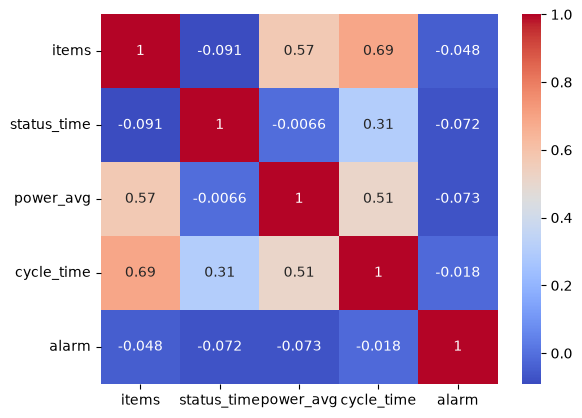

In [13]:
sns.heatmap(df.corr(numeric_only=True),cmap="coolwarm",annot=True)

<Axes: xlabel='asset', ylabel='power_avg'>

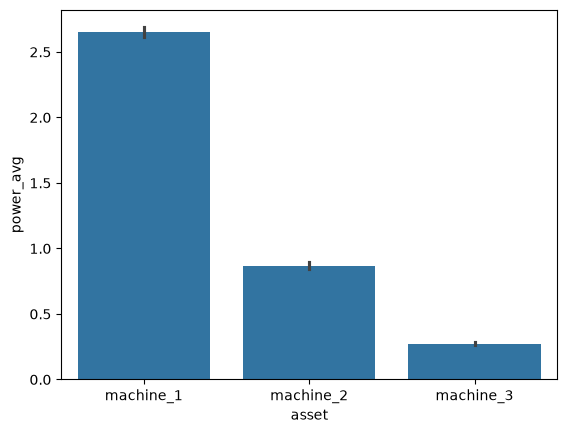

In [14]:
sns.barplot(data=df,x="asset",y="power_avg")

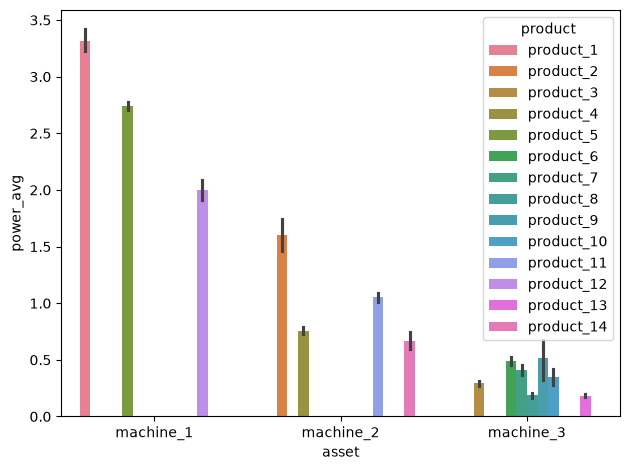

In [15]:
sns.barplot(data=df,x="asset",y="power_avg",hue="product")
plt.tight_layout()

<Axes: xlabel='power_avg', ylabel='Count'>

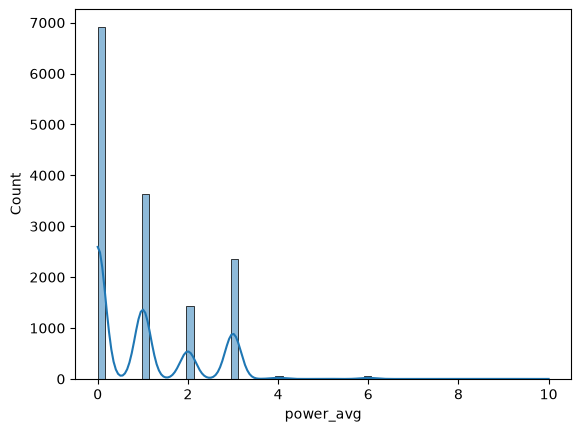

In [16]:
sns.histplot(data=df,x="power_avg",kde=True)

<Axes: xlabel='asset', ylabel='count'>

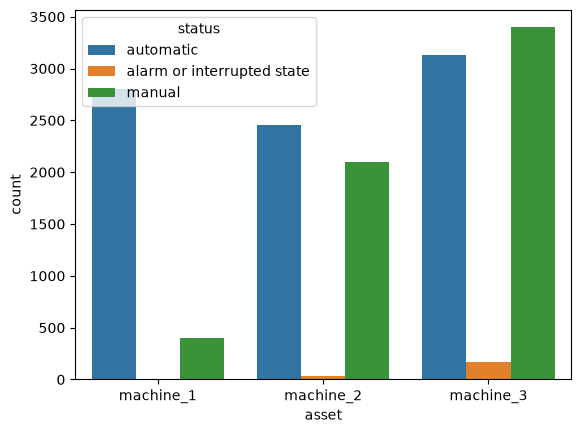

In [17]:
sns.countplot(data=df,x="asset",hue='status')

### there are poducts that want specific machines 

<Axes: xlabel='cycle_time', ylabel='power_avg'>

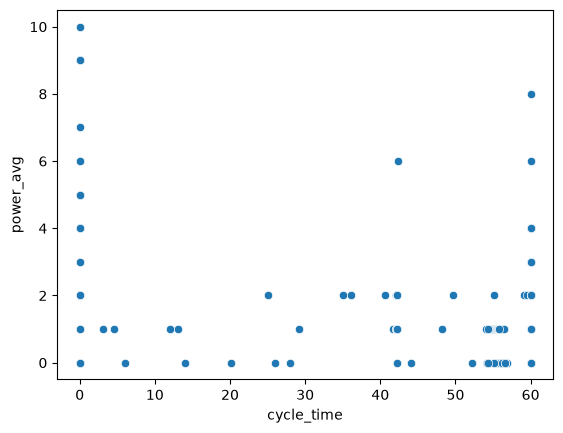

In [18]:
sns.scatterplot(data=df,x="cycle_time",y="power_avg")

<Axes: xlabel='cycle_time', ylabel='Count'>

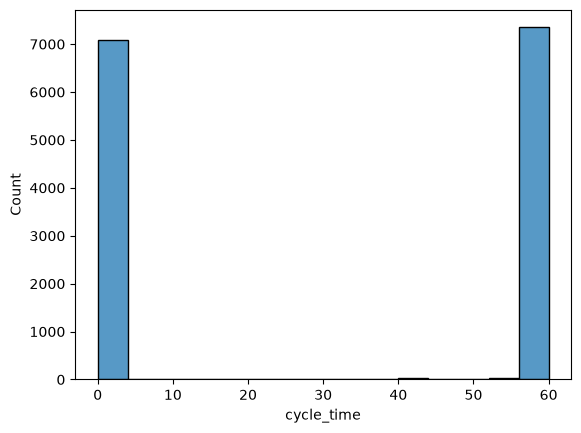

In [19]:
sns.histplot(data=df,x="cycle_time")

<Axes: xlabel='cycle_time', ylabel='items'>

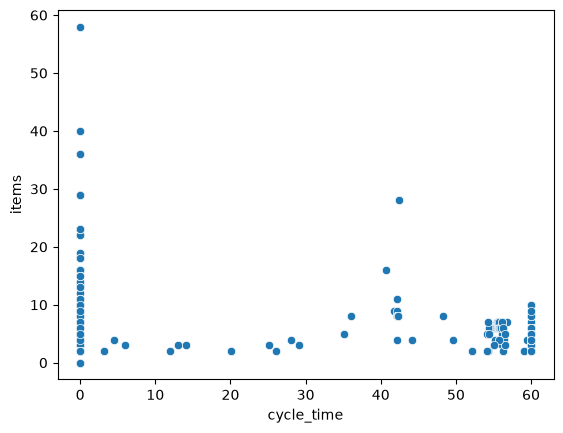

In [20]:
sns.scatterplot(data=df,x="cycle_time",y="items")

### how cycle time equal 0 when the machine produces items

<Axes: xlabel='count', ylabel='asset'>

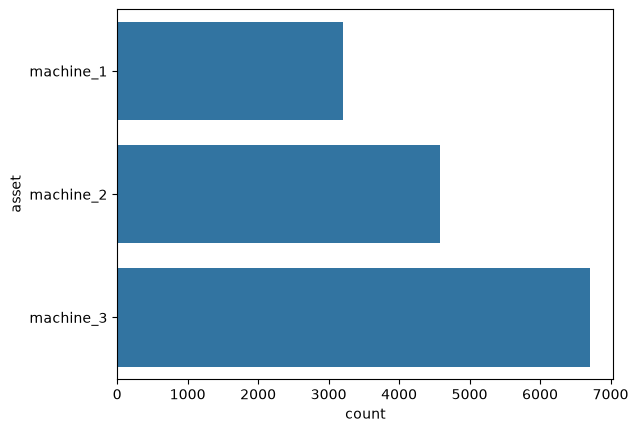

In [21]:
sns.countplot(df["asset"])

<Axes: xlabel='asset', ylabel='items'>

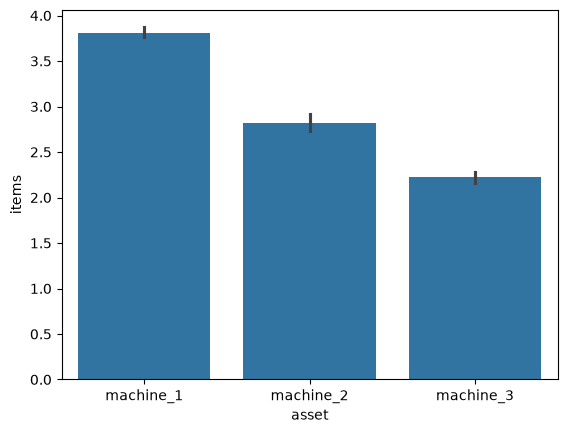

In [22]:
sns.barplot(data=df,x="asset",y="items")

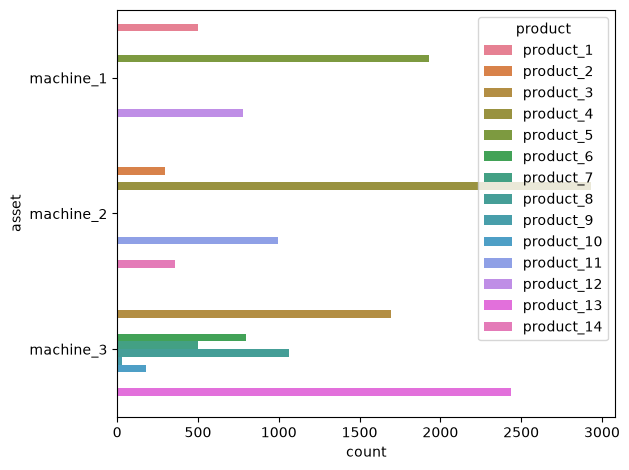

In [23]:
sns.countplot(data=df,y="asset",hue="product")
plt.tight_layout()

## Feature Engineering